# 06. Інтерпретація навчальної моделі

Відтворюємо зафіксовану Logistic Regression і навчаємо її лише на навчальній частині. Тестова частина не використовується для інтерпретації. Коефіцієнти описують модельні log-odds, а не причинний вплив.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.data_split import load_dataset, split_dataset
from src.preprocessing import prepare_xy
from src.evaluate import build_selected_model

path = root / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
train, test = split_dataset(load_dataset(path))
del test
X, y = prepare_xy(train)
model = build_selected_model().fit(X, y)
feature_names = model.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.Series(model.named_steps['model'].coef_[0], index=feature_names, name='coefficient')
assert len(coefficients) == len(feature_names)
ranked = coefficients.sort_values()
display(pd.concat([ranked.head(8), ranked.tail(8)]).to_frame())

,coefficient
numeric__tenure,-1.289492
categorical__Contract_Two year,-0.743031
categorical__InternetService_DSL,-0.290077
categorical__PhoneService_Yes,-0.238686
categorical__OnlineSecurity_Yes,-0.225572
categorical__MultipleLines_No,-0.217092
categorical__PaymentMethod_Mailed check,-0.202951
categorical__TechSupport_Yes,-0.195517
categorical__MultipleLines_No phone service,0.116171
numeric__MonthlyCharges,0.153709


## Як читати коефіцієнти

Числові ознаки стандартизовані: коефіцієнт відповідає зміні на одне стандартне відхилення після обробки пропусків. Категоріальні ознаки мають повне one-hot кодування без видаленої референтної категорії; окремий dummy-коефіцієнт не є порівнянням із явною базовою категорією. Відмінність коефіцієнтів двох категорій однієї ознаки дає модельний контраст за незмінних інших ознак.

,coefficient
categorical__Contract_Month-to-month,0.682854
categorical__Contract_One year,-0.062339
categorical__Contract_Two year,-0.743031


Контраст log-odds: помісячний мінус дворічний контракт: 1.426


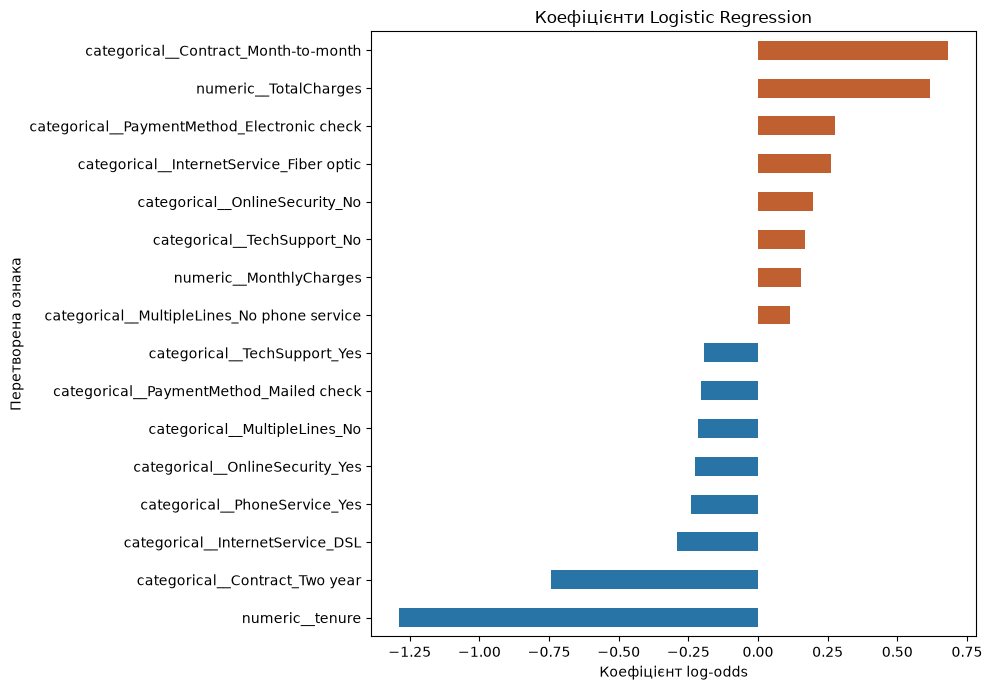

In [2]:
contract = coefficients.filter(like='categorical__Contract_')
display(contract.to_frame())
contrast = contract['categorical__Contract_Month-to-month'] - contract['categorical__Contract_Two year']
print(f'Контраст log-odds: помісячний мінус дворічний контракт: {contrast:.3f}')
extremes = pd.concat([ranked.head(8), ranked.tail(8)])
ax = extremes.plot.barh(figsize=(10, 7), color=['#2874a6' if value < 0 else '#c06030' for value in extremes])
ax.set(title='Коефіцієнти Logistic Regression', xlabel='Коефіцієнт log-odds', ylabel='Перетворена ознака')
plt.tight_layout()
plt.show()

## Обмеження

`tenure` і `TotalCharges` сильно корелюють; повне one-hot кодування, регуляризація й спільна наявність ознак впливають на коефіцієнти. Їхні абсолютні значення не є універсальною важливістю ознаки. Контракт та інші характеристики можуть бути недоступні або змінені на момент прогнозування. Ваги класів впливають на score, який без калібрування не слід трактувати як надійну ймовірність. Для незалежної оцінки потрібні нові дані.